# Бизнес-проблема

За последний месяц:
- рекламные расходы выросли на 65%;
- посещения лендинга выросли на 60%;
- регистрации выросли на 55%;
- количество новых платящих пользователей выросло только на 2%.

Необходимо выяснить, почему рост привлечения не приводит к сопоставимому росту продаж, и определить возможности улучшения эффективности маркетинга.
Указанные показатели задают исходный бизнес-контекст. Остальные результаты анализа не должны быть заранее определены.

## План исследования

Первоначальный план.

Проблема: нету роста платящих пользователей при финансировании маркетинга

1. **Проверить факты**, стоит проверить факты которые нам приподнесли для уверенности.
    - Рост расходов на рекламу
    - Рост посещения лендинга
    - Рост новых пользователей
    - Кол-во платящих пользователей
2. **Проверить каналы привлечения**, что-бы проверить мою первую мысль и для дальнейшего анализа увидим разницу между каналами.
    - Кол-во пользователей которые совершили оплату, успешные оплаты
    - CAC
    - Конверсия из регистрации в оплату

Дальше **план** будет строится в зависимости от ситуации


In [222]:
from pathlib import Path
import os
import math

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import plotly.express as px
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

BASE_DIR = Path.cwd().parent  # если запускаешь из папки scripts
load_dotenv(BASE_DIR / ".env")

engine = create_engine(os.getenv("DATABASE_URL"))

### Проверка фактов 
Предоставленные факты подтверждены.

C:\Temp\ipykernel_2176\3469263076.py:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


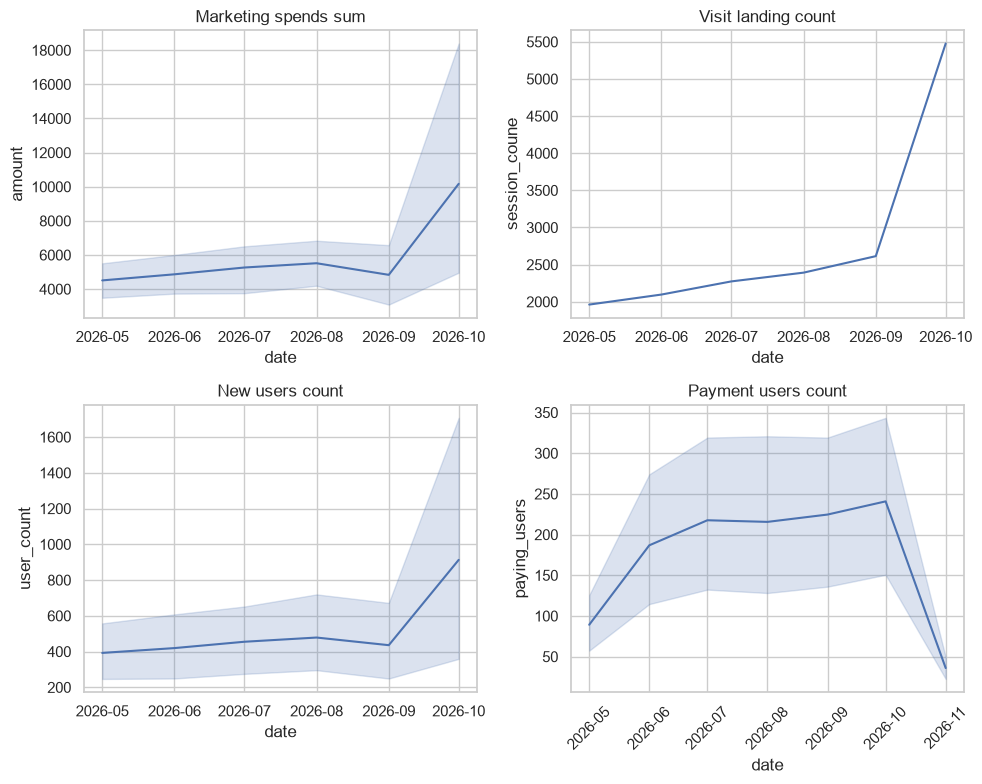

In [223]:
df_marketing_spend_by_channel = pd.read_sql(text("""
SELECT
    DATE_TRUNC('month', spend_date)::DATE as date,
    channel,
    SUM(COALESCE(spend_amount,0)) as amount
FROM marketing_spend m
GROUP BY 1,2
"""), engine)
df_marketing_spend_by_channel['date'] = pd.to_datetime(df_marketing_spend_by_channel['date'])
df_visit_landing = pd.read_sql(text("""
SELECT
    date_trunc('month', session_start) as date,
    COUNT(session_id) as session_coune
FROM web_sessions
GROUP BY 1
ORDER BY 1
"""), engine)
df_new_users = pd.read_sql(text("""
SELECT
    date_trunc('month', created_at) as date,
    LOWER(acquisition_channel) as channel,
    COUNT(DISTINCT user_id) as user_count
FROM users
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_payment_users_by_channel = pd.read_sql(text("""
WITH channels AS (
    SELECT DISTINCT
        LOWER(u.acquisition_channel) AS channel,
        u.user_id
    FROM users u
)

SELECT
    date_trunc('month', p.payment_time) AS date,
    c.channel,
    COUNT(DISTINCT p.user_id) AS paying_users
FROM channels c
LEFT JOIN payments p
    ON p.user_id = c.user_id
   AND p.payment_status = 'succeeded'
GROUP BY 1, c.channel
ORDER BY 1,paying_users DESC;
"""), engine)

fig, ax = plt.subplots(2,2,figsize=(10,8))

sns.set_style('darkgrid')

sns.lineplot(data=df_marketing_spend_by_channel,x='date',y='amount', ax=ax[0,0])
ax[0,0].set_title("Marketing spends sum")
sns.lineplot(data=df_visit_landing,x='date',y='session_coune', ax=ax[0,1])
ax[0,1].set_title("Visit landing count")
sns.lineplot(data=df_new_users,x='date',y='user_count', ax=ax[1,0])
ax[1,0].set_title("New users count")
sns.lineplot(data=df_payment_users_by_channel,x='date',y='paying_users', ax=ax[1,1])
ax[1,1].set_title("Payment users count")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

fig.show()

### Проверка каналов привлечения

При анализе было выявленое:

- пользоователи из канала social broad не заплатили ниразу за подписку. В следствии чего:
    - САС неопределен
    - Конверсия в покупку 0
    - Платящих пользователей 0

C:\Temp\ipykernel_2176\23418121.py:106: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


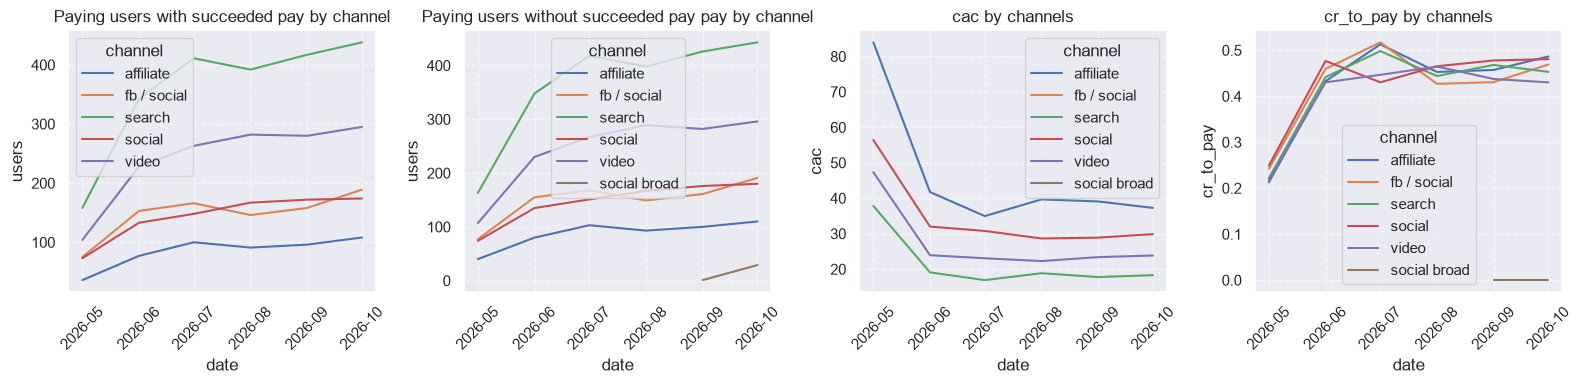

In [224]:
df_pay_users_succeeded = pd.read_sql(text("""
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
WHERE payment_time < '2026-11-01' AND payment_status = 'succeeded'
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_pay_users = pd.read_sql(text("""
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
WHERE payment_time < '2026-11-01'
GROUP BY 1,2
ORDER BY 1,2
"""), engine)
df_CAC = pd.read_sql(text("""
WITH mark_spends_by_month AS (
    SELECT
        DATE_TRUNC('month', spend_date) AS date,
        LOWER(channel) AS channel,
        SUM(COALESCE(spend_amount, 0)) AS amount
    FROM marketing_spend
    GROUP BY 1, 2
),
users_count AS (
    SELECT
        DATE_TRUNC('month', p.payment_time) AS date,
        LOWER(u.acquisition_channel) AS channel,
        COUNT(DISTINCT p.user_id) AS users
    FROM payments p
    JOIN users u
        ON u.user_id = p.user_id
    WHERE p.payment_time < '2026-11-01'
      AND p.payment_status = 'succeeded'
    GROUP BY 1, 2
)
SELECT
    COALESCE(m.date, uc.date)::date AS date,
    COALESCE(m.channel, uc.channel) AS channel,
    COALESCE(m.amount, 0) AS marketing_spend,
    COALESCE(uc.users, 0) AS paying_users,
    m.amount::numeric / NULLIF(uc.users, 0) AS cac
FROM mark_spends_by_month m
FULL OUTER JOIN users_count uc
    ON m.date = uc.date
   AND m.channel = uc.channel
ORDER BY 1, 2;
"""), engine)
df_CAC['date'] = pd.to_datetime(df_CAC['date'])
df_cr_to_pay = pd.read_sql(text("""
WITH user_count AS (
SELECT
    date_trunc('month', created_at) as date,
    LOWER(acquisition_channel) as channel,
    COUNT(DISTINCT user_id) as users
FROM users
GROUP BY 1,2
), pay_users AS (
SELECT
    date_trunc('month', p.payment_time) as date,
    LOWER(u.acquisition_channel) as channel,
    COUNT(DISTINCT p.user_id) as users
FROM payments p
LEFT JOIN users u ON u.user_id = p.user_id
LEFT JOIN user_count uc ON uc.date = date_trunc('month', p.payment_time) AND uc.channel = u.acquisition_channel
WHERE payment_time < '2026-11-01' AND payment_status = 'succeeded'
GROUP BY 1,2
)

SELECT
    uc.date,
    uc.channel,
    COALESCE(pu.users::numeric / uc.users,0) as cr_to_pay
FROM user_count uc
LEFT JOIN pay_users pu ON pu.date = uc.date AND pu.channel = uc.channel
ORDER BY 1,2
"""), engine)

fig, ax = plt.subplots(1,4,figsize=(16,4))

sns.set_style('darkgrid')

sns.lineplot(data=df_pay_users_succeeded,x='date',y='users', hue='channel', ax=ax[0])
ax[0].set_title("Paying users with succeeded pay by channel")
sns.lineplot(data=df_pay_users,x='date',y='users', hue='channel', ax=ax[1])
ax[1].set_title("Paying users without succeeded pay pay by channel")
sns.lineplot(data=df_CAC,x='date',y='cac',hue='channel', ax=ax[2])
ax[2].set_title("cac by channels")
sns.lineplot(data=df_cr_to_pay,x='date',y='cr_to_pay', hue='channel', ax=ax[3])
ax[3].set_title("cr_to_pay by channels")
for single_ax in ax.flatten():
    single_ax.tick_params(axis='x', rotation=45)
    single_ax.grid(True, linestyle='--', alpha=0.6)

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

fig.show()

## **Дальнейший план**

Для точного анализа нужно сделать воронку.
- узнать конверсию из trial в ключевое действие
- конверсия с ключевого действия в **успешную** оплату

### Воронка

Итоги анализа:

Все каналы по конверсии +-равны за исключением social broad, у него такие показатели:
 - конверсию из trial в ключевое действие 5%, что в 11.8 раз меньше чем у остальных каналов
 - конверсия в **успешную** покупку 0, в то время как у остальных каналов ~28%

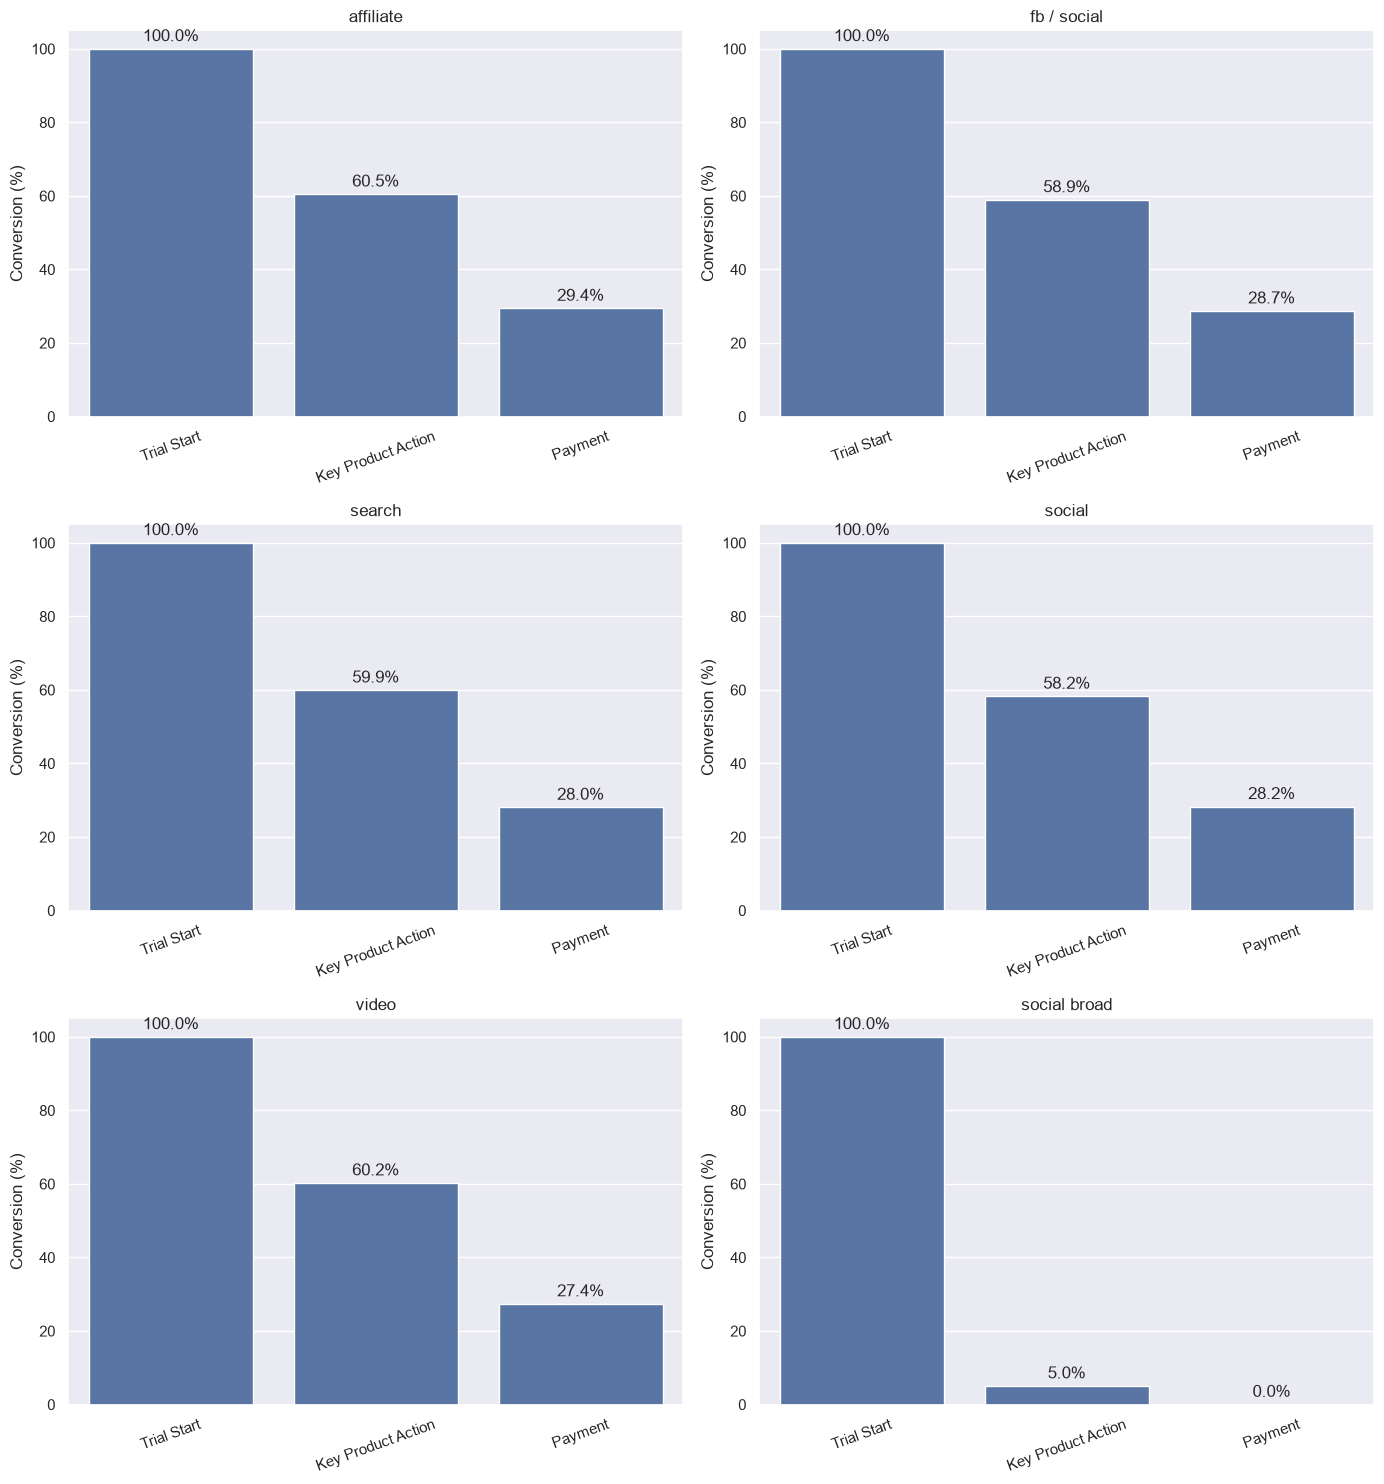

In [225]:
df_funnale_by_channels = pd.read_sql(text("""
WITH params AS (
    SELECT 'month'::text AS date_grain
),
landing_visit AS (
    SELECT
        date_trunc(p.date_grain, e.event_time) AS period,
        e.user_id,
        MIN(e.event_time) AS landing_time
    FROM events e
    CROSS JOIN params p
    WHERE e.event_name = 'landing_visit'
    GROUP BY 1, 2
),
registration AS (
    SELECT
        l.period,
        l.user_id,
        MIN(e.event_time) AS registration_time
    FROM landing_visit l
    JOIN events e
        ON e.user_id = l.user_id
       AND e.event_name = 'registration'
       AND e.event_time >= l.landing_time
    GROUP BY 1, 2
),
trial_start AS (
    SELECT
        r.period,
        r.user_id,
        MIN(e.event_time) AS trial_time
    FROM registration r
    JOIN events e
        ON e.user_id = r.user_id
       AND e.event_name = 'trial_start'
       AND e.event_time >= r.registration_time
    GROUP BY 1, 2
),
key_product_action AS (
    SELECT
        t.period,
        t.user_id,
        MIN(e.event_time) AS action_time
    FROM trial_start t
    JOIN events e
        ON e.user_id = t.user_id
       AND e.event_name = 'key_product_action'
       AND e.event_time >= t.trial_time
    GROUP BY 1, 2
),
payment_succeeded AS (
    SELECT
        t.period,
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
       AND p.payment_status = 'succeeded'
       AND p.payment_time >= t.trial_time
    GROUP BY 1, 2
)
SELECT
    l.period,
    LOWER(u.acquisition_channel) AS channel,
    -- 1.0 AS landing_users,
    -- COUNT(DISTINCT r.user_id)::numeric
    --     / NULLIF(COUNT(DISTINCT l.user_id), 0) AS registration_cr,
    COUNT(DISTINCT t.user_id)::numeric
        / NULLIF(COUNT(DISTINCT r.user_id), 0) AS trial_start_cr,

    COUNT(DISTINCT a.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0) AS key_action_cr,

    COUNT(DISTINCT ps.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0) AS payment_cr

FROM landing_visit l

LEFT JOIN registration r
    ON r.user_id = l.user_id
   AND r.period = l.period

LEFT JOIN trial_start t
    ON t.user_id = l.user_id
   AND t.period = l.period

LEFT JOIN key_product_action a
    ON a.user_id = l.user_id
   AND a.period = l.period

LEFT JOIN payment_succeeded ps
    ON ps.user_id = l.user_id
   AND ps.period = l.period

LEFT JOIN users u
    ON u.user_id = l.user_id

GROUP BY 1, 2
ORDER BY 1, 2
"""), engine)

metrics = [
    'trial_start_cr',
    'key_action_cr',
    'payment_cr'
]

stage_names = [
    'Trial Start',
    'Key Product Action',
    'Payment'
]

channels = df_funnale_by_channels['channel'].unique()

ncols = 2
nrows = math.ceil(len(channels) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 5 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, channel in enumerate(channels):
    df_channel = df_funnale_by_channels[
        df_funnale_by_channels['channel'] == channel
    ]

    funnel = (
        df_channel[metrics]
        .mean()
        .mul(100)
        .reset_index()
    )

    funnel.columns = ['stage', 'conversion']
    funnel['stage'] = stage_names

    sns.barplot(
        data=funnel,
        x='stage',
        y='conversion',
        ax=axes[i]
    )

    axes[i].set_title(channel)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Conversion (%)')
    axes[i].tick_params(axis='x', rotation=20)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', padding=3)

for j in range(len(channels), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Углублённый анализ: эффективность вариантов лендинга

На предыдущем этапе анализа я сравнил конверсию воронки по каналам привлечения и обнаружил, что канал `social broad` показывает слабые результаты по сравнению с другими каналами.

Однако агрегированные показатели по каналам не позволяют определить, с чем могут быть связаны эти различия. Поэтому я решил дополнительно исследовать конверсию в разрезе вариантов лендингов внутри каждого канала.

Это позволит проверить, различаются ли результаты между вариантами лендингов и может ли этот фактор быть связан с низкой конверсией исследуемого канала.

**В ходе исследования** над каналом social broad было обнаружено неожиданное: 
- у всех каналов вариант лендинга А показывает более лучшую конверсию по сравнению с вариантом В.
Разница конверсий у канала social broad:
    - Trial start -> Key Action, у варианта А 70%, у В 0%
    - Key Action -> Payment, тут у обоих 0
Разница конверсий у остальных каналов: 
    - Trial start -> Key Action, у варианта А больше чем у В в 3.5 раза
    - Key Action -> Payment, у варианта А больше чем у В на 3 раза

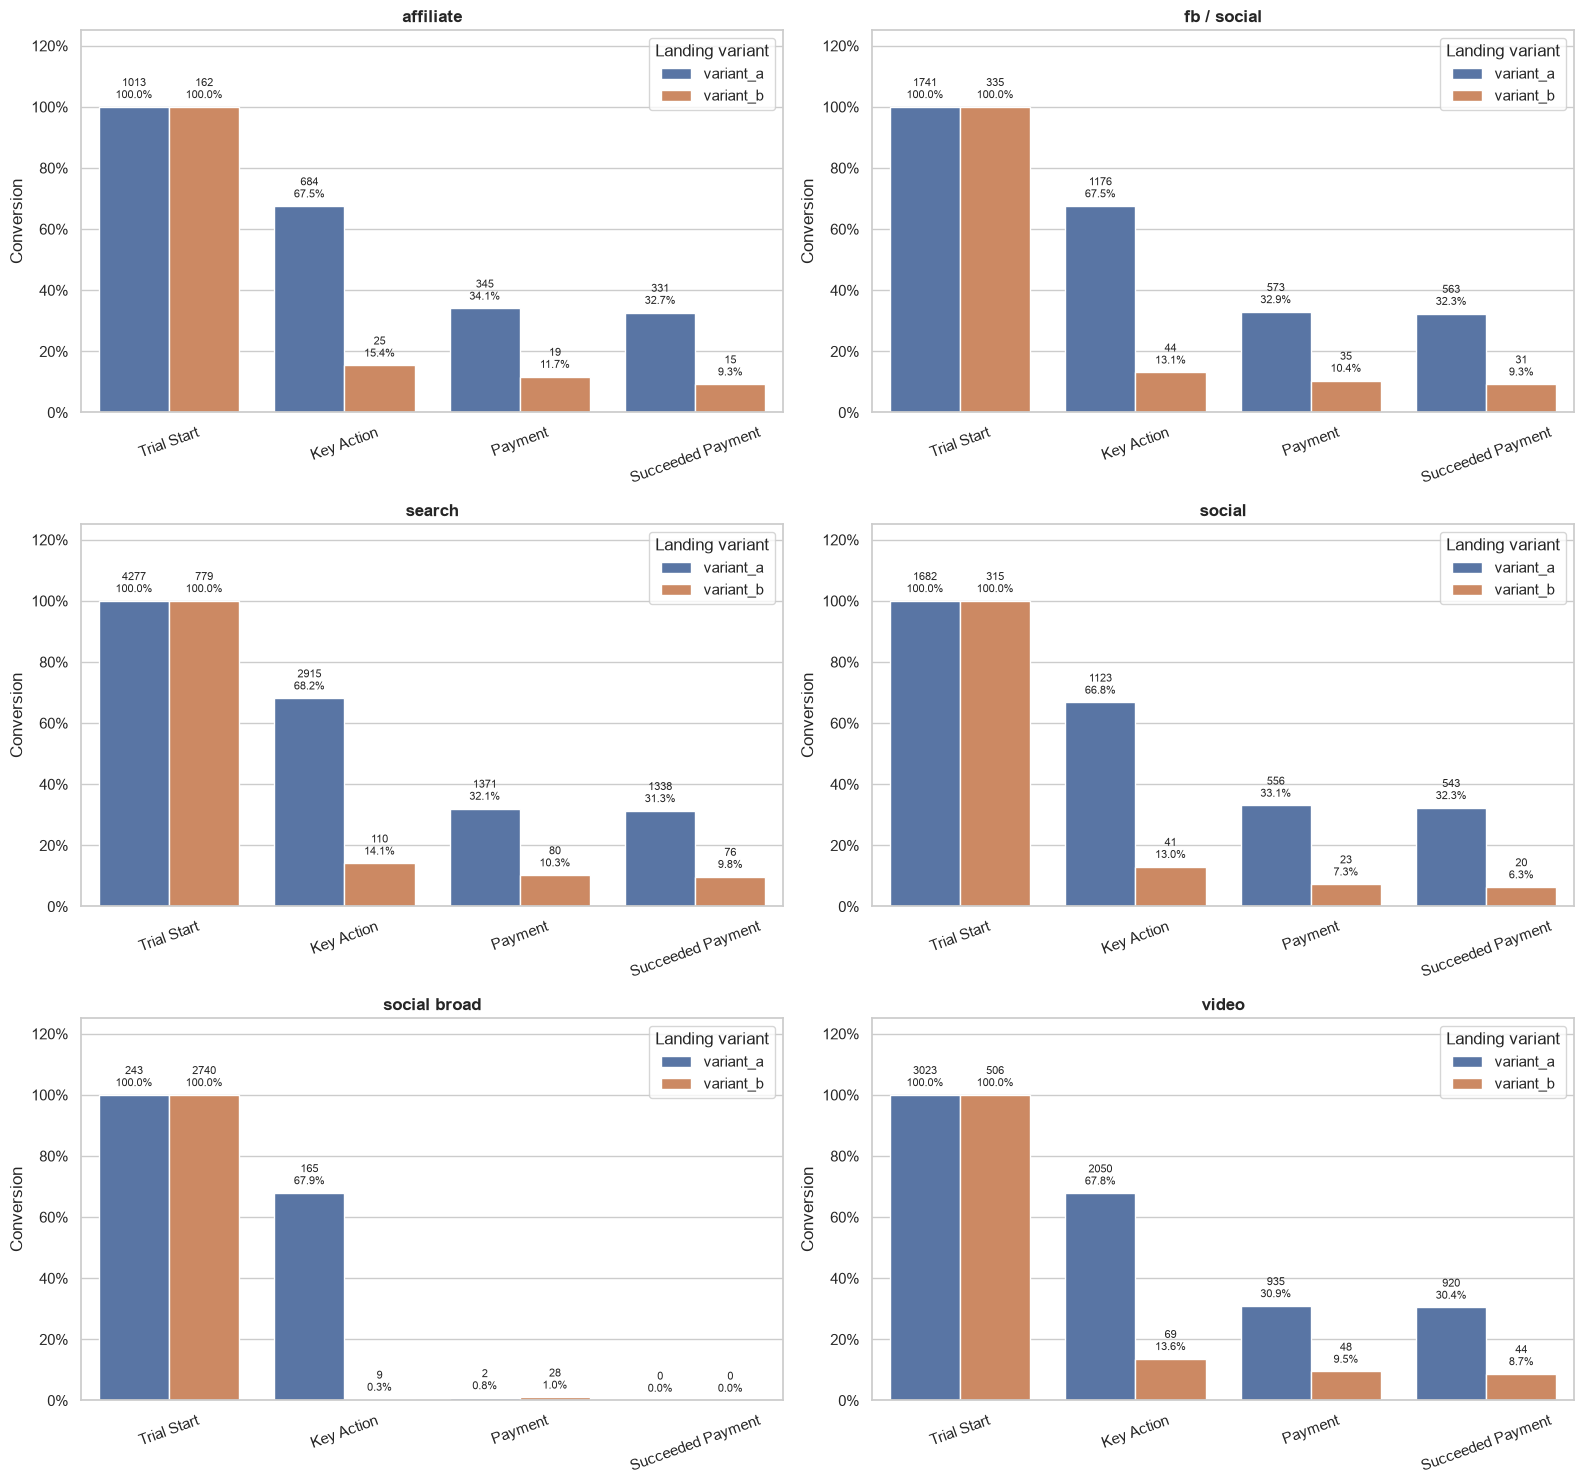

In [ ]:

df_funnel_by_landing_var = pd.read_sql(text("""
WITH landing_visit AS (
    SELECT
        e.user_id,
        MIN(e.event_time) AS landing_time
    FROM events e
    WHERE e.event_name = 'landing_visit'
    GROUP BY e.user_id
),

registration AS (
    SELECT
        l.user_id,
        MIN(e.event_time) AS registration_time
    FROM landing_visit l
    JOIN events e
        ON e.user_id = l.user_id
        AND e.event_name = 'registration'
        AND e.event_time >= l.landing_time
    GROUP BY l.user_id
),

trial_start AS (
    SELECT
        r.user_id,
        MIN(e.event_time) AS trial_time
    FROM registration r
    JOIN events e
        ON e.user_id = r.user_id
        AND e.event_name = 'trial_start'
        AND e.event_time >= r.registration_time
    GROUP BY r.user_id
),

key_product_action AS (
    SELECT
        t.user_id,
        MIN(e.event_time) AS action_time
    FROM trial_start t
    JOIN events e
        ON e.user_id = t.user_id
        AND e.event_name = 'key_product_action'
        AND e.event_time >= t.trial_time
    GROUP BY t.user_id
),

payment AS (
    SELECT
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
        AND p.payment_time >= t.trial_time
    GROUP BY t.user_id
),

payment_succeeded AS (
    SELECT
        t.user_id,
        MIN(p.payment_time) AS payment_time
    FROM trial_start t
    JOIN payments p
        ON p.user_id = t.user_id
        AND p.payment_status = 'succeeded'
        AND p.payment_time >= t.trial_time
    GROUP BY t.user_id
)

SELECT
    LOWER(u.acquisition_channel) AS acquisition_channel,
    LOWER(u.landing_variant) AS landing_variant,

    -- Абсолютные значения: уникальные пользователи
    COUNT(DISTINCT l.user_id) AS landing_visitors,
    COUNT(DISTINCT r.user_id) AS registrations,
    COUNT(DISTINCT t.user_id) AS trial_starts,
    COUNT(DISTINCT a.user_id) AS key_actions,
    COUNT(DISTINCT p.user_id) AS payments,
    COUNT(DISTINCT ps.user_id) AS succeeded_payments,

    -- Конверсии
    COUNT(DISTINCT t.user_id)::numeric
        / NULLIF(COUNT(DISTINCT r.user_id), 0)
        AS trial_start_cr,

    COUNT(DISTINCT a.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS key_action_cr,

    COUNT(DISTINCT p.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS payment_cr,

    COUNT(DISTINCT ps.user_id)::numeric
        / NULLIF(COUNT(DISTINCT t.user_id), 0)
        AS succeeded_payment_cr

FROM landing_visit l
LEFT JOIN registration r
    ON r.user_id = l.user_id
LEFT JOIN trial_start t
    ON t.user_id = l.user_id
LEFT JOIN key_product_action a
    ON a.user_id = l.user_id
LEFT JOIN payment p
    ON p.user_id = l.user_id
LEFT JOIN payment_succeeded ps
    ON ps.user_id = l.user_id
LEFT JOIN users u
    ON u.user_id = l.user_id

GROUP BY
    LOWER(u.acquisition_channel),
    LOWER(u.landing_variant)

ORDER BY
    acquisition_channel,
    landing_variant;
"""), engine)

stages = [
    ('trial_start_cr', 'trial_starts', 'Trial Start'),
    ('key_action_cr', 'key_actions', 'Key Action'),
    ('payment_cr', 'payments', 'Payment'),
    ('succeeded_payment_cr', 'succeeded_payments', 'Succeeded Payment')
]

stage_order = [stage[2] for stage in stages]
sns.set_theme(style='whitegrid')

channels = sorted(
    df_funnel_by_landing_var['acquisition_channel'].dropna().unique()
)

ncols = 2
nrows = math.ceil(len(channels) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(16, 5 * nrows),
    squeeze=False
)

axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]

    df_channel = df_funnel_by_landing_var[
        df_funnel_by_landing_var['acquisition_channel'] == channel
    ].copy()

    plot_rows = []

    for _, row in df_channel.iterrows():
        for metric_col, count_col, stage_name in stages:

            plot_rows.append({
                'landing_variant': row['landing_variant'],
                'stage': stage_name,
                'conversion': row[metric_col],
                'users': row[count_col]
            })

    df_plot = pd.DataFrame(plot_rows)

    hue_order = sorted(
        df_plot['landing_variant'].dropna().unique()
    )

    sns.barplot(
        data=df_plot,
        x='stage',
        y='conversion',
        hue='landing_variant',
        order=stage_order,
        hue_order=hue_order,
        errorbar=None,
        ax=ax
    )

    for variant, container in zip(hue_order, ax.containers):

        for stage_idx, bar in enumerate(container):

            height = bar.get_height()

            if pd.isna(height):
                continue

            stage_name = stage_order[stage_idx]

            matching_rows = df_plot[
                (df_plot['landing_variant'] == variant)
                & (df_plot['stage'] == stage_name)
            ]

            if matching_rows.empty:
                continue

            users = matching_rows['users'].iloc[0]

            if pd.isna(users):
                continue

            ax.annotate(
                f'{int(users)}\n{height:.1%}',
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center',
                va='bottom',
                fontsize=8
            )

    ax.set_title(channel, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Conversion')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1.25)
    ax.tick_params(axis='x', rotation=20)

    ax.legend(title='Landing variant')

for j in range(len(channels), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## **Проверка результатов**

Было найдено неприбыльный канал привлечения, который не приносит прибыли/платящих пользователей от слова совсем.
Для того что-бы проверить корректность результатов будут предприняты след. действий:
1. **Проверка затрат маркетинга**
     - проверить сопоставление прибыли и затрат САС.
     - проверить затраты по каналам привлечения.
2. **Сопоставление затрат**
     - сопоставить затраты, колв-о регситраций,чистая прибыль(прибыль - затраты на маркетинг) без канала social broad, сопоставить уже с наличием этого канала

### Проверка затрат маркетинга

У пользователей канала socail broad вообще нету успешных заказов, это значит что платящих пользователей нету. 
И из-за этогоо невозможно посчитать САС для этого канала.

За октябрь затраты у social broad в 4.34 раза больше чем у медианы по остальным каналам! 

Это нам показывает что social broad сжирает бюджет маркетинга.

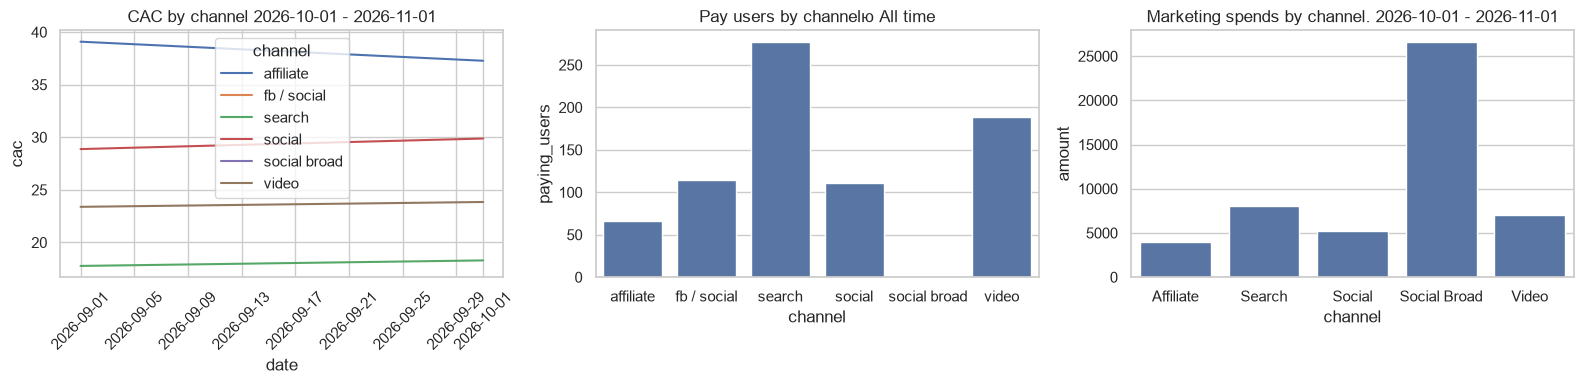

In [227]:
fig, ax = plt.subplots(1,3,figsize=(16,4))

sns.lineplot(df_CAC.query("date >= '2026-09-01' & date < '2026-11-01'"),x='date',y='cac', hue='channel',ax=ax[0])
ax[0].set_title("CAC by channel 2026-10-01 - 2026-11-01")
sns.barplot(df_payment_users_by_channel.sort_values('channel'), x='channel', y='paying_users',ax=ax[1], errorbar=None)
ax[1].set_title("Pay users by channelю All time")
sns.barplot(df_marketing_spend_by_channel.query("date >= '2026-10-01' & date < '2026-11-01'").sort_values('channel'), x='channel', y='amount',ax=ax[2], errorbar=None)
ax[2].set_title("Marketing spends by channel. 2026-10-01 - 2026-11-01")

ax[0].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.tight_layout()

### Сопоставление затрат

При сравнении было выяывлеены слудющие закономерности:

In [228]:
df_marketing_spend_without_social_broad = df_marketing_spend_by_channel.query("channel != 'Social Broad'").groupby('date').agg(
    amount = ('amount', 'sum')
).reset_index()
df_marketing_spend_without_social_broad['diff'] = ((df_marketing_spend_without_social_broad['amount'] - df_marketing_spend_without_social_broad['amount'].shift(1)) / df_marketing_spend_without_social_broad['amount'].shift(1)) * 100
df_marketing_spend_without_social_broad.iloc[0,2] = 0

df_profit_by_channels = pd.read_sql(text("""
WITH channels AS (
    SELECT DISTINCT
        LOWER(acquisition_channel) AS channel
    FROM users
),
months AS (
    SELECT generate_series(
        DATE '2026-05-01',
        DATE '2026-10-01',
        INTERVAL '1 month'
    ) AS date
),
revenue AS (
    SELECT
        date_trunc('month', p.payment_time) AS date,
        LOWER(u.acquisition_channel) AS channel,
        SUM(p.amount) AS revenue
    FROM payments p
    JOIN users u ON u.user_id = p.user_id
    WHERE p.payment_status = 'succeeded'
      AND p.payment_time >= DATE '2026-05-01'
      AND p.payment_time < DATE '2026-11-01'
    GROUP BY 1, 2
),
marketing AS (
    SELECT
        date_trunc('month', spend_date) AS date,
        LOWER(channel) AS channel,
        SUM(spend_amount) AS marketing_cost
    FROM marketing_spend
    WHERE spend_date >= DATE '2026-05-01'
      AND spend_date < DATE '2026-11-01'
    GROUP BY 1, 2
)
SELECT
    m.date,
    c.channel,
    COALESCE(r.revenue, 0) AS revenue,
    COALESCE(ms.marketing_cost, 0) AS marketing_cost,
    COALESCE(r.revenue, 0)
        - COALESCE(ms.marketing_cost, 0) AS net_profit
FROM months m
CROSS JOIN channels c
LEFT JOIN revenue r
    ON r.date = m.date
   AND r.channel = c.channel
LEFT JOIN marketing ms
    ON ms.date = m.date
   AND ms.channel = c.channel
ORDER BY 1, 2;
"""), engine)
df_profit_by_channels['date'] = pd.to_datetime(df_profit_by_channels['date'])
df_profit_by_channels_without_social_broad = df_profit_by_channels.query("channel != 'social broad'")

#### Без канала social broad

Траты на маркетинг растут в историческом темпе, новые пользователя регистрируются в том же темпе, прибыль растет.

(-1000.0, 40000.0)

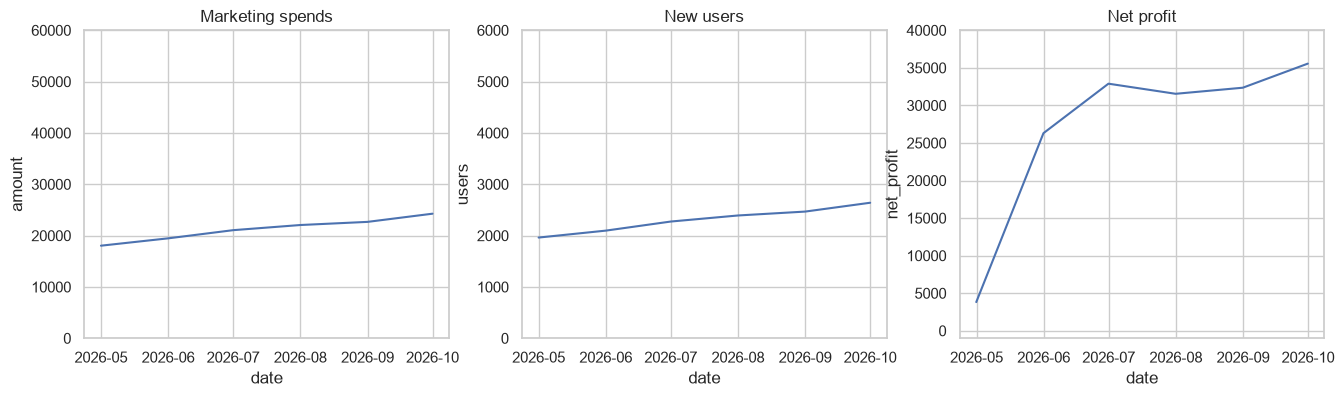

In [229]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.lineplot(df_marketing_spend_without_social_broad, x='date', y='amount',ax=ax[0])
ax[0].set_title("Marketing spends")
ax[0].set_ylim(0,60000)
sns.lineplot(df_new_users.query("channel != 'social broad'").groupby(['date']).agg(users = ('user_count','sum')), x='date', y='users',ax=ax[1])
ax[1].set_title("New users")
ax[1].set_ylim(0,6000)
sns.lineplot(df_profit_by_channels_without_social_broad.groupby('date').agg(net_profit=('net_profit','sum')), x='date', y='net_profit',ax=ax[2])
ax[2].set_title("Net profit")
ax[2].set_ylim(-1000,40000)

#### С каналом social broad

Траты на маркетинг взлетели, с 24к до 50к. Новых пользователей стало больше на +-50%. Выолвая прибыль упала с 31к до 9к в последний мес.

(0.0, 40000.0)

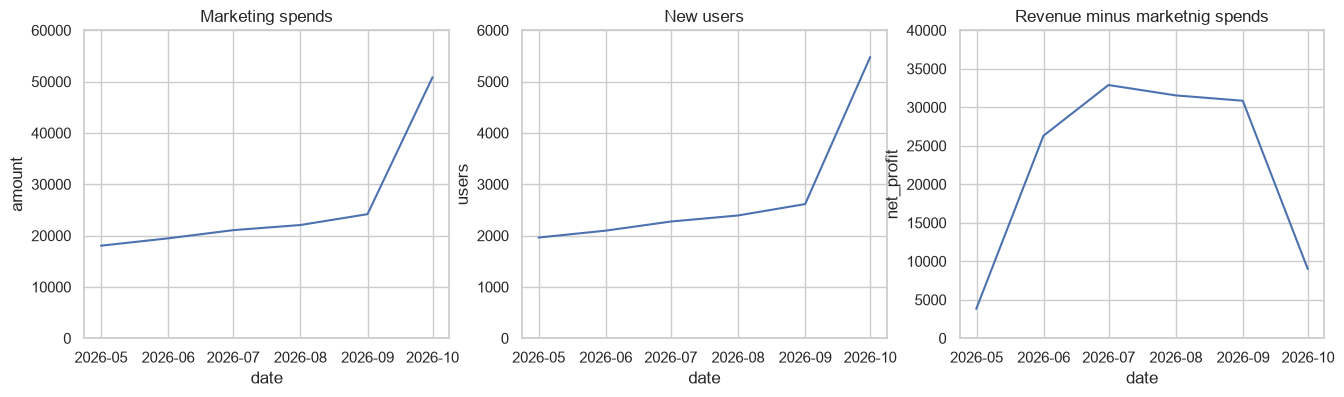

In [230]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.lineplot(df_marketing_spend_by_channel.groupby(['date']).agg(amount = ('amount','sum')), x='date', y='amount',ax=ax[0])
ax[0].set_title("Marketing spends")
ax[0].set_ylim(0,60000)
sns.lineplot(df_new_users.groupby(['date']).agg(users = ('user_count','sum')), x='date', y='users',ax=ax[1])
ax[1].set_title("New users")
ax[1].set_ylim(0,6000)
sns.lineplot(df_profit_by_channels.groupby('date').agg(net_profit=('net_profit','sum')), x='date', y='net_profit',ax=ax[2])
ax[2].set_title("Revenue minus marketnig spends")
ax[2].set_ylim(0,40000)

## Итоговый вывод

**Проблема:** расходы на маркетинг, количество посещений лендингов и регистраций выросли, однако рост числа платящих пользователей оказался значительно ниже ожидаемого.

**В ходе исследования было обнаружено:**

- **Канал social broad.** Запущен 27 сентября и за исследуемый период не принёс ни одного платящего пользователя. Расходы на канал примерно в 3,5 раза превышают медианные расходы на остальные каналы привлечения. В результате за октябрь выручка за вычетом маркетинговых расходов составила около 9 000 вместо потенциальных 35 000 при исключении расходов на social broad из расчёта.
- **Вариант лендинга B.** Демонстрирует более низкую конверсию в ключевое продуктовое действие и успешную оплату по сравнению с вариантом A.

**Рекомендации:**

1. Приостановить финансирование social broad до выяснения причин его низкой эффективности.
2. Проверить качество привлекаемого трафика, настройки рекламной кампании и корректность отслеживания оплат.
3. Исследовать причины низкой конверсии лендинга B и оценить возможность улучшения его эффективности.